**This notebook merges the figures of `llm-and-baseline-vs-gt.ipynb` and `process-llm-vs-baseline.ipynb` into one six-panel figure.**

Data, metrics and plotting code are taken unchanged from the two source notebooks.

| Merged panel | Source |
|---|---|
| (a) | `llm-and-baseline-vs-gt` (a) |
| (b) | `llm-and-baseline-vs-gt` (b) |
| (c) | `process-llm-vs-baseline` (a), spans rows 1–2, with MG / PROTAC titles and counts |
| (d) | `process-llm-vs-baseline` (b) |
| (e) | `process-llm-vs-baseline` (c) |
| (f) | `process-llm-vs-baseline` (d), same size, full width |

In [8]:
import json
import os
import re
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
from matplotlib.ticker import MultipleLocator
from scipy import stats

DEEP_TEAL     = "#2D4F54"
ROYAL_PURPLE  = "#7B539E"
SOFT_LAVENDER = "#B8A0D2"
FOREST_GREEN  = "#5A9448"
MUTED_PLUM    = "#9E4A78"
DARK_SLATE    = "#3A3D4A"
HATCH_GRAY    = "#9A9A9A"

AIME_PALETTE = [DEEP_TEAL, ROYAL_PURPLE, SOFT_LAVENDER,
                FOREST_GREEN, MUTED_PLUM, DARK_SLATE]

# rcParams of process-llm-vs-baseline.ipynb (global style of the merged figure)
PROCESS_RCPARAMS = {
    "font.family":       "serif",
    "font.serif":        ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset":  "stix",
    "font.size":         18,
    "axes.facecolor":    "white",
    "axes.edgecolor":    DARK_SLATE,
    "axes.linewidth":    1.2,
    "axes.labelcolor":   DARK_SLATE,
    "axes.labelsize":    18,
    "axes.titlesize":    18,
    "axes.spines.top":   True,
    "axes.spines.right": True,
    "axes.prop_cycle":   plt.cycler("color", AIME_PALETTE),
    "axes.grid":         False,
    "xtick.color":         DARK_SLATE,
    "ytick.color":         DARK_SLATE,
    "xtick.labelsize":     16,
    "ytick.labelsize":     16,
    "xtick.major.width":   1.0,
    "ytick.major.width":   1.0,
    "xtick.major.size":    4.5,
    "ytick.major.size":    4.5,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "xtick.direction":     "out",
    "ytick.direction":     "out",
    "legend.frameon":    False,
    "legend.fontsize":   16,
    "legend.labelcolor": DARK_SLATE,
    "figure.facecolor":  "white",
    "figure.dpi":        150,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "savefig.pad_inches": 0.02,
    "savefig.facecolor": "white",
    "lines.linewidth":   1.8,
    "lines.markersize":  6.5,
    # editable, embedded TrueType text in the PDF (journal production requirement)
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
}

# rcParams of llm-and-baseline-vs-gt.ipynb (AIME_RCPARAMS overridden by TIMES_RC),
# applied only while its two panels are created and drawn
GT_AIME_RCPARAMS = {
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":         10,
    "axes.facecolor":    "white",
    "axes.edgecolor":    DARK_SLATE,
    "axes.linewidth":    1.0,
    "axes.labelcolor":   DARK_SLATE,
    "axes.labelsize":    10,
    "axes.spines.top":   True,
    "axes.spines.right": True,
    "axes.prop_cycle":   plt.cycler("color", AIME_PALETTE),
    "axes.grid":         False,
    "xtick.color":       DARK_SLATE,
    "ytick.color":       DARK_SLATE,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.major.size":  3.5,
    "ytick.major.size":  3.5,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "out",
    "ytick.direction":   "out",
    "legend.frameon":    False,
    "legend.fontsize":   8.5,
    "legend.labelcolor": DARK_SLATE,
    "lines.linewidth":   1.4,
    "lines.markersize":  4.5,
    "hatch.linewidth":   0.6,
    "hatch.color":       HATCH_GRAY,
}
TIMES_RC = {
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
}
GT_RCPARAMS = {**GT_AIME_RCPARAMS, **TIMES_RC}

plt.rcParams.update(PROCESS_RCPARAMS)
# hatches are rendered at draw time, so their style has to be global
plt.rcParams.update({"hatch.linewidth": 0.6, "hatch.color": HATCH_GRAY})

COL_MG = ROYAL_PURPLE
COL_PT = MUTED_PLUM


# LLM and baseline vs. ground truth (`llm-and-baseline-vs-gt.ipynb`)

In [9]:
ROOT = Path("/Users/yaochenr/project/molecular_glue_extractor/output/results")
MG_LLM_MECH_DIRS = [ROOT / d for d in ["260504_2355", "260504_2308", "260505_0038"]]
MG_LLM_EXP_DIRS  = [ROOT / d for d in ["260504_2123", "260504_2306", "260505_0037"]]
MG_BL_MECH_PATH  = ROOT / "260326_1614" / "record_based_evaluation_results.json"
MG_BL_EXP_PATH   = ROOT / "260326_1612" / "record_based_evaluation_results.json"
PROTAC_LLM_MECH_DIRS = [ROOT / d for d in ["260424_1729", "260502_1821", "260502_1606"]]
PROTAC_LLM_EXP_DIRS  = [ROOT / d for d in ["260424_1727", "260502_1819", "260502_1600"]]
PROTAC_BL_MECH_PATH  = ROOT / "260424_1732" / "record_based_evaluation_results.json"
PROTAC_BL_EXP_PATH   = ROOT / "260424_1733" / "record_based_evaluation_results.json"


def load_json(path):
    with open(path) as f:
        return json.load(f)


mg_llm_mech_raw = [load_json(d / "record_based_evaluation_results.json") for d in MG_LLM_MECH_DIRS]
mg_llm_exp_raw  = [load_json(d / "record_based_evaluation_results.json") for d in MG_LLM_EXP_DIRS]
mg_bl_mech_raw  = load_json(MG_BL_MECH_PATH)
mg_bl_exp_raw   = load_json(MG_BL_EXP_PATH)

protac_llm_mech_raw = [load_json(d / "record_based_evaluation_results.json") for d in PROTAC_LLM_MECH_DIRS]
protac_llm_exp_raw  = [load_json(d / "record_based_evaluation_results.json") for d in PROTAC_LLM_EXP_DIRS]
protac_bl_mech_raw  = load_json(PROTAC_BL_MECH_PATH)
protac_bl_exp_raw   = load_json(PROTAC_BL_EXP_PATH)


def safe_div(a, b):
    return a / b if b > 0 else float("nan")


def prf(tp, fp, fn):
    p = safe_div(tp, tp + fp)
    r = safe_div(tp, tp + fn)
    f1 = safe_div(2 * p * r, p + r) if (p == p and r == r and (p + r) > 0) else float("nan")
    return p, r, f1


def sd_nonan(vals):
    valid = [v for v in vals if v == v]
    return np.std(valid, ddof=1) if len(valid) > 1 else float("nan")


def record_prf(part1):
    return (part1["precision_records"], part1["recall_records"], part1["f1_score_records"])


mg_mech_arr = np.array([record_prf(r["part1_record_level"]) for r in mg_llm_mech_raw]).T
mg_exp_arr  = np.array([record_prf(r["part1_record_level"]) for r in mg_llm_exp_raw]).T
mg_bl_mech  = list(record_prf(mg_bl_mech_raw["part1_record_level"]))
mg_bl_exp   = list(record_prf(mg_bl_exp_raw["part1_record_level"]))

protac_mech_arr = np.array([record_prf(r["part1_record_level"]) for r in protac_llm_mech_raw]).T
protac_exp_arr  = np.array([record_prf(r["part1_record_level"]) for r in protac_llm_exp_raw]).T
protac_bl_mech  = list(record_prf(protac_bl_mech_raw["part1_record_level"]))
protac_bl_exp   = list(record_prf(protac_bl_exp_raw["part1_record_level"]))

GT_FIELDS = ["Cell_Line", "Assay",
             "DC50", "DC50_units", "DC50_h", "Dmax", "Dmax_h", "Dmax_conc"]
GT_MECH_FIELDS = GT_FIELDS


def micro_with_sd(raw_list, fields):
    out = {}
    for field in fields:
        tp_total = fp_total = fn_total = 0
        ps, rs, fs = [], [], []
        for r in raw_list:
            pfm = r["part2_entry_level"]["per_field_metrics"].get(field)
            if pfm is None:
                continue
            tp, fp, fn = pfm["tp"], pfm["fp"], pfm["fn"]
            tp_total += tp; fp_total += fp; fn_total += fn
            p_i, r_i, f1_i = prf(tp, fp, fn)
            ps.append(p_i); rs.append(r_i); fs.append(f1_i)
        p, r, f1 = prf(tp_total, fp_total, fn_total)
        out[field] = {
            "tp": tp_total, "fp": fp_total, "fn": fn_total,
            "p": p,   "p_sd":  sd_nonan(ps),
            "r": r,   "r_sd":  sd_nonan(rs),
            "f1": f1, "f1_sd": sd_nonan(fs),
        }
    return out


def f1_from_pfm(pfm, fields=GT_MECH_FIELDS):
    out = {}
    for f in fields:
        if f not in pfm:
            out[f] = float("nan"); continue
        _, _, f1 = prf(pfm[f]["tp"], pfm[f]["fp"], pfm[f]["fn"])
        out[f] = f1
    return out


mg_field_mech     = micro_with_sd(mg_llm_mech_raw, GT_MECH_FIELDS)
protac_field_mech = micro_with_sd(protac_llm_mech_raw, GT_MECH_FIELDS)
mg_field_f1       = {f: mg_field_mech[f]["f1"] for f in GT_MECH_FIELDS}
protac_field_f1   = {f: protac_field_mech[f]["f1"] for f in GT_MECH_FIELDS}

mg_bl_field_f1     = f1_from_pfm(mg_bl_mech_raw["part2_entry_level"]["per_field_metrics"])
protac_bl_field_f1 = f1_from_pfm(protac_bl_mech_raw["part2_entry_level"]["per_field_metrics"])

print(f"MG     : {len(mg_llm_mech_raw)} replicates (mech + exp) + 2 baselines")
print(f"PROTAC : {len(protac_llm_mech_raw)} replicates (mech + exp) + 2 baselines")


MG     : 3 replicates (mech + exp) + 2 baselines
PROTAC : 3 replicates (mech + exp) + 2 baselines


# LLM vs. baseline (`process-llm-vs-baseline.ipynb`)

In [10]:
MG_PATH = "/Users/yaochenr/project/molecular_glue_extractor/output/results/260502_llm_baseline_eva_glue/llm_vs_baseline_results.json"
PT_PATH = "/Users/yaochenr/project/molecular_glue_extractor/output/results/260502_llm_baseline_eva_protacs/llm_vs_baseline_results.json"

with open(MG_PATH) as f:
    mg_results = json.load(f)
with open(PT_PATH) as f:
    pt_results = json.load(f)


def parse_numeric(val):
    if val is None:
        return np.nan
    s = str(val).strip()
    if not s:
        return np.nan
    s = re.sub(r'^[≈><=]+\s*', '', s)
    try:
        return float(s)
    except ValueError:
        return np.nan


def is_missing_value(val):
    if val is None:
        return True
    s = str(val).strip()
    return s == "" or s.lower() == "nan" or s.lower() == "none"


CMP_FIELDS = ["Assay", "Cell_Line", "DC50", "Dmax", "DC50_units", "DC50_h", "Dmax_h", "Dmax_conc"]


def extract(results):
    """Extract matched DC50/Dmax pairs, field counts, and topology stats from a results JSON."""
    gc = results["global_counts"]
    topo = {
        "l1": gc["intersection_l1"],
        "l2": gc["intersection_l2"],
        "l3": gc["intersection_l3"],
        "llm_only": gc["llm_only"],
        "bl_only": gc["baseline_only"],
        "total_llm": results["total_llm_records"],
        "total_bl": results["total_baseline_records"],
    }

    dc50_bl, dc50_llm = [], []
    dmax_bl, dmax_llm = [], []
    all_baseline, all_llm = [], []

    for doi, info in results["per_doi"].items():
        recs = info.get("records", {})
        for level_key in ("intersection_l1", "intersection_l2", "intersection_l3"):
            for item in recs.get(level_key, []):
                b, l = item["baseline"], item["llm"]
                all_baseline.append(b)
                all_llm.append(l)

                bd = parse_numeric(b.get("DC50"))
                ld = parse_numeric(l.get("DC50"))
                if np.isfinite(bd) and np.isfinite(ld):
                    dc50_bl.append(bd)
                    dc50_llm.append(ld)

                bm = parse_numeric(b.get("Dmax"))
                lm = parse_numeric(l.get("Dmax"))
                if np.isfinite(bm) and np.isfinite(lm):
                    dmax_bl.append(bm)
                    dmax_llm.append(lm)

        for item in recs.get("baseline_only", []):
            all_baseline.append(item["baseline"])
        for item in recs.get("llm_only", []):
            all_llm.append(item["llm"])

    counts_bl = {f: sum(1 for r in all_baseline if not is_missing_value(r.get(f))) for f in CMP_FIELDS}
    counts_llm = {f: sum(1 for r in all_llm if not is_missing_value(r.get(f))) for f in CMP_FIELDS}

    return {
        "topo": topo,
        "dc50_bl": np.array(dc50_bl),
        "dc50_llm": np.array(dc50_llm),
        "dmax_bl": np.array(dmax_bl),
        "dmax_llm": np.array(dmax_llm),
        "counts_bl": counts_bl,
        "counts_llm": counts_llm,
    }


def gain_label(bl, llm):
    if bl > 0:
        return f"{(llm - bl) / bl * 100:+.0f}%"
    return "De novo"


mg = extract(mg_results)
pt = extract(pt_results)

print("MG  total LLM:", mg_results["total_llm_records"], "  total baseline:", mg_results["total_baseline_records"])
print("PT  total LLM:", pt_results["total_llm_records"], "  total baseline:", pt_results["total_baseline_records"])
print(f"MG  DC50 pairs: {len(mg['dc50_bl'])}, Dmax pairs: {len(mg['dmax_bl'])}")
print(f"PT  DC50 pairs: {len(pt['dc50_bl'])}, Dmax pairs: {len(pt['dmax_bl'])}")


MG  total LLM: 246   total baseline: 136
PT  total LLM: 714   total baseline: 372
MG  DC50 pairs: 52, Dmax pairs: 22
PT  DC50 pairs: 145, Dmax pairs: 152


# Panel drawing functions

In [14]:
VENN_LLM_FILL = SOFT_LAVENDER
VENN_LLM_EDGE = ROYAL_PURPLE
VENN_BL_FILL  = DARK_SLATE
VENN_BL_EDGE  = DARK_SLATE
VENN_L3       = FOREST_GREEN
VENN_L2       = FOREST_GREEN
VENN_L1       = DEEP_TEAL


def _estimate_lens_area(cx_llm, cx_bl, cy, a_llm, b_llm, a_bl, b_bl, n=400):
    left = max(cx_llm - a_llm, cx_bl - a_bl)
    right = min(cx_llm + a_llm, cx_bl + a_bl)
    top = min(cy + min(b_llm, b_bl), cy + b_bl)
    bot = max(cy - min(b_llm, b_bl), cy - b_bl)
    if left >= right or bot >= top:
        return 0.0
    xs = np.linspace(left, right, n)
    ys = np.linspace(bot, top, n)
    xx, yy = np.meshgrid(xs, ys)
    in_llm = ((xx - cx_llm) / a_llm) ** 2 + ((yy - cy) / b_llm) ** 2 <= 1.0
    in_bl = ((xx - cx_bl) / a_bl) ** 2 + ((yy - cy) / b_bl) ** 2 <= 1.0
    cell_area = (right - left) * (top - bot) / (n * n)
    return np.sum(in_llm & in_bl) * cell_area


def draw_venn(ax, topo, title, title_color):
    """Stratified Venn diagram; labels show record count and percentage of baseline records."""
    l1, l2, l3 = topo["l1"], topo["l2"], topo["l3"]
    llm_only, bl_only = topo["llm_only"], topo["bl_only"]
    total_llm, total_bl = topo["total_llm"], topo["total_bl"]
    overlap = l1 + l2 + l3

    n_l3, n_l2, n_l1 = overlap, l1 + l2, l1
    pct_bl_only = bl_only / total_bl * 100
    pct_llm_only = llm_only / total_bl * 100
    pct_l3 = n_l3 / total_bl * 100
    pct_l2 = n_l2 / total_bl * 100
    pct_l1 = n_l1 / total_bl * 100
    pct_overlap = pct_l3

    aspect = 1.6
    b_bl = 0.22
    b_llm = b_bl * np.sqrt(total_llm / total_bl)
    a_bl = aspect * b_bl
    a_llm = aspect * b_llm

    baseline_ellipse_area = np.pi * a_bl * b_bl
    target_lens_area = (pct_overlap / 100.0) * baseline_ellipse_area

    cy = 0.50
    gap_lo, gap_hi = 0.01, a_llm + a_bl
    for _ in range(50):
        gap_mid = (gap_lo + gap_hi) / 2
        cx_llm_test = 0.5 - gap_mid / 2
        cx_bl_test = 0.5 + gap_mid / 2
        area = _estimate_lens_area(cx_llm_test, cx_bl_test, cy, a_llm, b_llm, a_bl, b_bl, n=400)
        if area > target_lens_area:
            gap_lo = gap_mid
        else:
            gap_hi = gap_mid
    gap = (gap_lo + gap_hi) / 2
    cx_llm = 0.5 - gap / 2
    cx_bl = 0.5 + gap / 2

    lens_left = cx_bl - a_bl
    lens_right = cx_llm + a_llm
    lens_cx = (lens_left + lens_right) / 2
    lens_cy = cy
    lens_b = min(b_llm, b_bl)

    b_max = max(b_llm, b_bl)
    x_min = cx_llm - a_llm - 0.005
    x_max = cx_bl + a_bl + 0.06
    y_min = cy - b_max - 0.13
    y_max = cy + b_max + 0.13

    ellipse_llm = Ellipse((cx_llm, cy), 2 * a_llm, 2 * b_llm,
                          facecolor=VENN_LLM_FILL, alpha=0.40, lw=1.5,
                          edgecolor=VENN_LLM_EDGE, zorder=1)
    ellipse_bl = Ellipse((cx_bl, cy), 2 * a_bl, 2 * b_bl,
                         facecolor=VENN_BL_FILL, alpha=0.18, lw=1.5,
                         edgecolor=VENN_BL_EDGE, zorder=1)
    ax.add_patch(ellipse_llm)
    ax.add_patch(ellipse_bl)

    clip_bl = Ellipse((cx_bl, cy), 2 * a_bl, 2 * b_bl,
                      transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(clip_bl)
    l3_fill = Ellipse((cx_llm, cy), 2 * a_llm, 2 * b_llm,
                      facecolor=VENN_L3, edgecolor='none', alpha=0.55, zorder=2)
    ax.add_patch(l3_fill)
    l3_fill.set_clip_path(clip_bl)
    lens_half_width = (lens_right - lens_left) / 2
    nested_aspect = lens_half_width / lens_b if lens_b > 0 else 1.4
    r_max = lens_b * 0.75
    r_l2 = r_max * np.sqrt(pct_l2 / pct_l3) if pct_l3 > 0 else 0
    r_l1 = r_max * np.sqrt(pct_l1 / pct_l3) if pct_l3 > 0 else 0
    r_l1 = max(r_l1, 0.018)

    e_l2 = Ellipse((lens_cx, lens_cy), 2 * nested_aspect * r_l2, 2 * r_l2,
                   facecolor=VENN_L2, edgecolor="white", lw=1.2, alpha=0.92, zorder=3)
    ax.add_patch(e_l2)
    e_l1 = Ellipse((lens_cx, lens_cy), 2 * nested_aspect * r_l1, 2 * r_l1,
                   facecolor=VENN_L1, edgecolor="white", lw=1.2, alpha=1.0, zorder=4)
    ax.add_patch(e_l1)

    ax.text(cx_llm - a_llm * 0.45, cy, f"AutoTPD Only\n{llm_only} ({pct_llm_only:.1f}%)",
            fontsize=17, fontweight="bold", ha="center", va="center",
            color=ROYAL_PURPLE, zorder=5)

    # count + percentage labels do not fit inside the lens, so the BL-only and
    # L1-L3 labels sit outside the ellipses with leader arrows
    def _callout(text, target, label_xy, color, va, ha="center"):
        ax.annotate(text, xy=target, xytext=label_xy,
                    fontsize=16, fontweight="bold", color=color,
                    ha=ha, va=va, zorder=6,
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.1,
                                    shrinkA=2, shrinkB=0,
                                    connectionstyle="arc3,rad=0.0"))

    top_y = cy + b_max + 0.03
    bot_y = cy - b_max - 0.03

    _callout(f"Baseline Only\n{bl_only} ({pct_bl_only:.1f}%)",
             target=(cx_bl + a_bl * 0.70, cy + b_bl * 0.25),
             label_xy=(cx_bl + a_bl + 0.05, top_y), color=DARK_SLATE,
             va="bottom", ha="right")

    l3_target_y = lens_cy + (r_l2 + lens_b) / 2 * 0.85
    _callout(f"L3: {n_l3} ({pct_l3:.1f}%)",
             target=(lens_cx, l3_target_y),
             label_xy=(lens_cx - 0.12, top_y), color=DEEP_TEAL, va="bottom")

    _callout(f"L2: {n_l2} ({pct_l2:.1f}%)",
             target=(lens_cx - nested_aspect * (r_l1 + r_l2) / 2, lens_cy),
             label_xy=(lens_cx - 0.20, bot_y), color=DEEP_TEAL, va="top")

    _callout(f"L1: {n_l1} ({pct_l1:.1f}%)",
             target=(lens_cx, lens_cy),
             label_xy=(lens_cx + 0.22, bot_y), color=DEEP_TEAL, va="top")

    ax.set_title(title, fontsize=20, fontweight="bold", color=title_color, pad=6)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    ax.axis("off")


In [19]:
GT_TICK_FS   = 17
GT_LABEL_FS  = 17
GT_LEGEND_FS = 15
BASELINE_LW   = 2.4
BASELINE_DASH = (0, (3.2, 1.6))


def draw_gt_scores(ax):
    """llm-and-baseline-vs-gt.ipynb, panel (a): record-level P / R / F1."""
    metric_labels = ["Precision", "Recall", r"F$_1$-score"]
    x = np.arange(len(metric_labels))
    bar_w = 0.20
    offsets = np.array([-1.5, -0.5, 0.5, 1.5]) * bar_w

    bar_specs = [
        (mg_mech_arr,     mg_bl_mech,     ROYAL_PURPLE, None,  offsets[0]),
        (protac_mech_arr, protac_bl_mech, MUTED_PLUM,   None,  offsets[1]),
        (mg_exp_arr,      mg_bl_exp,      ROYAL_PURPLE, "///", offsets[2]),
        (protac_exp_arr,  protac_bl_exp,  MUTED_PLUM,   "///", offsets[3]),
    ]

    rng = np.random.default_rng(42)

    for llm_mat, bl_vals, color, hatch, off in bar_specs:
        bar_x = x + off
        means = llm_mat.mean(axis=1)
        sds   = llm_mat.std(axis=1, ddof=1)
        ax.bar(bar_x, means, width=bar_w, color=color, alpha=0.88,
               edgecolor=DARK_SLATE, linewidth=0.6, hatch=hatch, zorder=2)
        ax.errorbar(bar_x, means, yerr=sds, fmt="none", color=DARK_SLATE,
                    linewidth=0.8, capsize=2.2, capthick=0.8, zorder=4)
        for j, col_vals in enumerate(llm_mat):
            jitter = rng.uniform(-bar_w * 0.30, bar_w * 0.30, size=len(col_vals))
            ax.scatter(bar_x[j] + jitter, col_vals, s=8, color=DARK_SLATE,
                       alpha=0.7, linewidths=0.25, edgecolors="white", zorder=5)
        for j, bv in enumerate(bl_vals):
            ax.plot([bar_x[j] - bar_w / 2, bar_x[j] + bar_w / 2], [bv, bv],
                    color=DARK_SLATE, linestyle=BASELINE_DASH, lw=BASELINE_LW,
                    solid_capstyle="butt", zorder=6)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels, fontsize=GT_TICK_FS)
    ax.set_ylim(-0.04, 1.06)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.yaxis.set_minor_locator(MultipleLocator(0.25))
    ax.tick_params(axis="x", labelsize=GT_TICK_FS)
    ax.tick_params(axis="y", labelsize=GT_TICK_FS)
    ax.tick_params(which="minor", length=2.0, width=0.6, direction="out")
    ax.set_ylabel("Score", fontsize=GT_LABEL_FS)
    ax.set_xlim(-0.55, len(metric_labels) - 0.45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_position(("data", -0.04))


def draw_gt_fields(ax):
    """llm-and-baseline-vs-gt.ipynb, panel (b): per-field F1, baseline vs LLM."""
    FIELD_LABELS_SHORT = {
        "Cell_Line":  "Cell Line",
        "Assay":      "Assay",
        "DC50":       r"DC$_{50}$",
        "DC50_units": "units",
        "DC50_h":     "hours",
        "Dmax":       r"D$_{\max}$",
        "Dmax_h":     "hours",
        "Dmax_conc":  "conc.",
    }
    field_labels_b = [FIELD_LABELS_SHORT[f] for f in GT_FIELDS]

    y_positions   = np.arange(len(GT_FIELDS))[::-1]
    DOMAIN_OFFSET = {"MG": +0.20, "PROTAC": -0.20}
    DOMAIN_COLOR  = {"MG": ROYAL_PURPLE, "PROTAC": MUTED_PLUM}
    DOMAIN_DATA   = {
        "MG":     (mg_bl_field_f1,     mg_field_f1),
        "PROTAC": (protac_bl_field_f1, protac_field_f1),
    }
    for idx, field in enumerate(GT_FIELDS):
        if idx % 2 == 0:
            ax.axhspan(y_positions[idx] - 0.45, y_positions[idx] + 0.45,
                       color="#F0F0F0", zorder=0)

    for idx, field in enumerate(GT_FIELDS):
        y_base = y_positions[idx]
        for domain in ("MG", "PROTAC"):
            y     = y_base + DOMAIN_OFFSET[domain]
            color = DOMAIN_COLOR[domain]
            bl_dict, llm_dict = DOMAIN_DATA[domain]
            bl_v  = bl_dict.get(field, np.nan)
            llm_v = llm_dict.get(field, np.nan)
            if not np.isnan(bl_v) and not np.isnan(llm_v):
                ax.plot([bl_v, llm_v], [y, y], color=color, lw=0.9,
                        alpha=0.75, zorder=2)
            if not np.isnan(bl_v):
                ax.scatter(bl_v, y, s=46, facecolors="white",
                           edgecolors=color, linewidths=1.1, zorder=4,
                           marker="o")
            if not np.isnan(llm_v):
                ax.scatter(llm_v, y, s=24, facecolors=color,
                           edgecolors=color, linewidths=0.5, zorder=5,
                           marker="o")

    ax.set_yticks(y_positions)
    ax.set_yticklabels(field_labels_b, fontsize=GT_TICK_FS)

    # same physical offset as in the original figure (0.125 x 4.88 in axes width)
    arrow_trans = ax.get_yaxis_transform() + mtransforms.ScaledTranslation(
        -0.61, 0, ax.figure.dpi_scale_trans)
    CHILD_FIELDS = {"DC50_units", "DC50_h", "Dmax_h", "Dmax_conc"}
    for idx, field in enumerate(GT_FIELDS):
        if field in CHILD_FIELDS:
            ax.text(
                0, y_positions[idx], "↳",
                transform=arrow_trans,
                ha="right", va="center",
                fontsize=GT_TICK_FS,
                fontfamily="DejaVu Sans",
                color=DARK_SLATE,
                clip_on=False,
            )
    ax.set_ylim(y_positions[-1] - 0.55, y_positions[0] + 0.55)
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel(r"F$_1$-score", fontsize=GT_LABEL_FS, labelpad=6)
    ax.tick_params(axis="x", labelsize=GT_TICK_FS)
    ax.tick_params(axis="y", labelsize=GT_TICK_FS)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.25))
    ax.tick_params(which="minor", length=2.0, width=0.6, direction="out")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def gt_legend_handles():
    NEUTRAL = "#BFBFBF"
    return [
        mpatches.Patch(facecolor=ROYAL_PURPLE, edgecolor=DARK_SLATE, alpha=0.88,
                       linewidth=0.6, label="Molecular Glue"),
        mpatches.Patch(facecolor=MUTED_PLUM, edgecolor=DARK_SLATE, alpha=0.88,
                       linewidth=0.6, label="PROTAC"),
        mpatches.Patch(facecolor=NEUTRAL, edgecolor=DARK_SLATE, linewidth=0.6,
                       label="L2"),
        mpatches.Patch(facecolor=NEUTRAL, edgecolor=DARK_SLATE, linewidth=0.6,
                       hatch="///", label="L1"),
        mlines.Line2D([], [], color=DARK_SLATE, linestyle=BASELINE_DASH,
                      lw=BASELINE_LW,
                      marker="o", markerfacecolor="white",
                      markeredgecolor=DARK_SLATE, markersize=5,
                      label="Baseline (database)"),
        mlines.Line2D([], [], color=DARK_SLATE, lw=0,
                      marker="o", markerfacecolor=DARK_SLATE,
                      markersize=4.5, label="LLM extraction"),
    ]


def venn_legend(ax, **placement):
    venn_handles = [
        mpatches.Patch(facecolor=FOREST_GREEN, alpha=0.55, label="L3"),
        mpatches.Patch(facecolor=FOREST_GREEN, alpha=0.95, label="L2"),
        mpatches.Patch(facecolor=DEEP_TEAL,                 label="L1"),
    ]
    placement = {"loc": "upper center", "bbox_to_anchor": (0.5, 0.04), **placement}
    ax.legend(handles=venn_handles, ncol=3, fontsize=20,
              handlelength=1.4, handleheight=0.9, columnspacing=0.7,
              handletextpad=0.4, labelcolor=DARK_SLATE, **placement)


def draw_dc50(ax):
    """process-llm-vs-baseline.ipynb, panel (b): DC50 baseline vs LLM."""
    ax.scatter(pt["dc50_bl"], pt["dc50_llm"], color=COL_PT, marker="o",
               s=70, alpha=0.55, edgecolors="white", linewidths=0.4, zorder=2)
    ax.scatter(mg["dc50_bl"], mg["dc50_llm"], color=COL_MG, marker="^",
               s=75, alpha=0.55, edgecolors="white", linewidths=0.4, zorder=3)

    dc50_all_bl = np.concatenate([mg["dc50_bl"], pt["dc50_bl"]])
    dc50_all_llm = np.concatenate([mg["dc50_llm"], pt["dc50_llm"]])
    lo = min(dc50_all_bl.min(), dc50_all_llm.min()) * 0.5
    hi = max(dc50_all_bl.max(), dc50_all_llm.max()) * 2
    ax.plot([lo, hi], [lo, hi], "--", color=DARK_SLATE, lw=1, alpha=0.45, zorder=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Baseline DC$_{50}$ (nM)", fontsize=19)
    ax.set_ylabel("AutoTPD DC$_{50}$ (nM)", fontsize=19)
    ax.tick_params(axis="both", labelsize=17)
    ax.set_aspect("equal")

    r_mg, _ = stats.pearsonr(np.log10(mg["dc50_bl"]), np.log10(mg["dc50_llm"]))
    r_pt, _ = stats.pearsonr(np.log10(pt["dc50_bl"]), np.log10(pt["dc50_llm"]))
    handles = [
        Line2D([0], [0], marker="^", color="none",
               markerfacecolor=COL_MG, markeredgecolor="white", markeredgewidth=0.5,
               markersize=14, alpha=0.85, label=f"MG: $r$ = {r_mg:.3f}"),
        Line2D([0], [0], marker="o", color="none",
               markerfacecolor=COL_PT, markeredgecolor="white", markeredgewidth=0.5,
               markersize=14, alpha=0.85, label=f"PROTAC: $r$ = {r_pt:.3f}"),
    ]
    ax.legend(handles=handles, loc="lower right", fontsize=17,
              handlelength=0.9, handletextpad=0.4, borderpad=0.3,
              labelcolor=[COL_MG, COL_PT])


def draw_dmax(ax):
    """process-llm-vs-baseline.ipynb, panel (c): Dmax baseline vs LLM."""
    ax.scatter(pt["dmax_bl"], pt["dmax_llm"], color=COL_PT, marker="o",
               s=70, alpha=0.55, edgecolors="white", linewidths=0.4, zorder=2)
    ax.scatter(mg["dmax_bl"], mg["dmax_llm"], color=COL_MG, marker="^",
               s=75, alpha=0.55, edgecolors="white", linewidths=0.4, zorder=3)
    ax.plot([0, 110], [0, 110], "--", color=DARK_SLATE, lw=1, alpha=0.45, zorder=1)
    ax.set_xlim(0, 110)
    ax.set_ylim(0, 110)
    ax.set_xlabel("Baseline D$_{max}$ (%)", fontsize=20)
    ax.set_ylabel("AutoTPD D$_{max}$ (%)", fontsize=20)
    ax.tick_params(axis="both", labelsize=17)
    ax.set_aspect("equal")

    r_mg_d, _ = stats.pearsonr(mg["dmax_bl"], mg["dmax_llm"])
    r_pt_d, _ = stats.pearsonr(pt["dmax_bl"], pt["dmax_llm"])
    handles = [
        Line2D([0], [0], marker="^", color="none",
               markerfacecolor=COL_MG, markeredgecolor="white", markeredgewidth=0.5,
               markersize=14, alpha=0.85,
               label=f"MG: $r$ = {r_mg_d:.3f}"),
        Line2D([0], [0], marker="o", color="none",
               markerfacecolor=COL_PT, markeredgecolor="white", markeredgewidth=0.5,
               markersize=14, alpha=0.85,
               label=f"PROTAC: $r$ = {r_pt_d:.3f}"),
    ]
    ax.legend(handles=handles, loc="lower right", fontsize=18,
              handlelength=0.9, handletextpad=0.4, borderpad=0.3,
              labelcolor=[COL_MG, COL_PT])


def draw_counts(ax):
    """process-llm-vs-baseline.ipynb, panel (d): non-null value count per field."""
    x = np.arange(len(CMP_FIELDS))
    w = 0.18
    offsets = [-0.40, -0.20, +0.06, +0.26]

    vals_mg_bl  = [mg["counts_bl"][f] for f in CMP_FIELDS]
    vals_mg_llm = [mg["counts_llm"][f] for f in CMP_FIELDS]
    vals_pt_bl  = [pt["counts_bl"][f] for f in CMP_FIELDS]
    vals_pt_llm = [pt["counts_llm"][f] for f in CMP_FIELDS]

    ax.bar(x + offsets[0], vals_mg_bl, w, color=COL_MG, alpha=0.40,
           edgecolor="white", linewidth=0.5, label="Baseline (MG)")
    bars_mg_llm = ax.bar(x + offsets[1], vals_mg_llm, w, color=COL_MG,
                         edgecolor="white", linewidth=0.5, label="LLM (MG)")
    ax.bar(x + offsets[2], vals_pt_bl, w, color=COL_PT, alpha=0.40,
           edgecolor="white", linewidth=0.5, label="Baseline (PROTAC)")
    bars_pt_llm = ax.bar(x + offsets[3], vals_pt_llm, w, color=COL_PT,
                         edgecolor="white", linewidth=0.5, label="LLM (PROTAC)")

    y_offset = max(max(vals_mg_llm), max(vals_pt_llm)) * 0.020

    def _place_gain(bar, text, color):
        x_pos = bar.get_x() + bar.get_width() / 2
        ax.text(x_pos, bar.get_height() + y_offset, text,
                ha="center", va="bottom",
                fontsize=18, fontweight="bold", color=color)

    for bar, bl, llm in zip(bars_mg_llm, vals_mg_bl, vals_mg_llm):
        _place_gain(bar, gain_label(bl, llm), COL_MG)
    for bar, bl, llm in zip(bars_pt_llm, vals_pt_bl, vals_pt_llm):
        _place_gain(bar, gain_label(bl, llm), COL_PT)

    field_labels = ["Assay", "Cell line",
                    "DC$_{50}$", "D$_{max}$",
                    "DC$_{50}$ units", "DC$_{50}$ hours",
                    "D$_{max}$ hours",  "D$_{max}$ conc."]
    ax.set_xticks(x)
    ax.set_xticklabels(field_labels, fontsize=21)
    ax.set_ylabel("Records with non-null field", fontsize=21)
    ax.tick_params(axis="y", labelsize=17)
    ax.set_xlim(-0.49, len(CMP_FIELDS) - 0.45)

    ax.legend(ncol=2, loc="upper right", fontsize=18,
              handlelength=1.4, handleheight=0.9, columnspacing=1.0,
              handletextpad=0.4)
    ax.set_ylim(0, max(max(vals_mg_llm), max(vals_pt_llm)) * 1.24)


def add_panel_label(ax, label, x_off, y_off, fontsize=22, va="bottom"):
    ax.text(x_off, y_off, label, transform=ax.transAxes,
            fontsize=fontsize, fontweight="bold", va=va, ha="left",
            color=DARK_SLATE)


# Merged figure

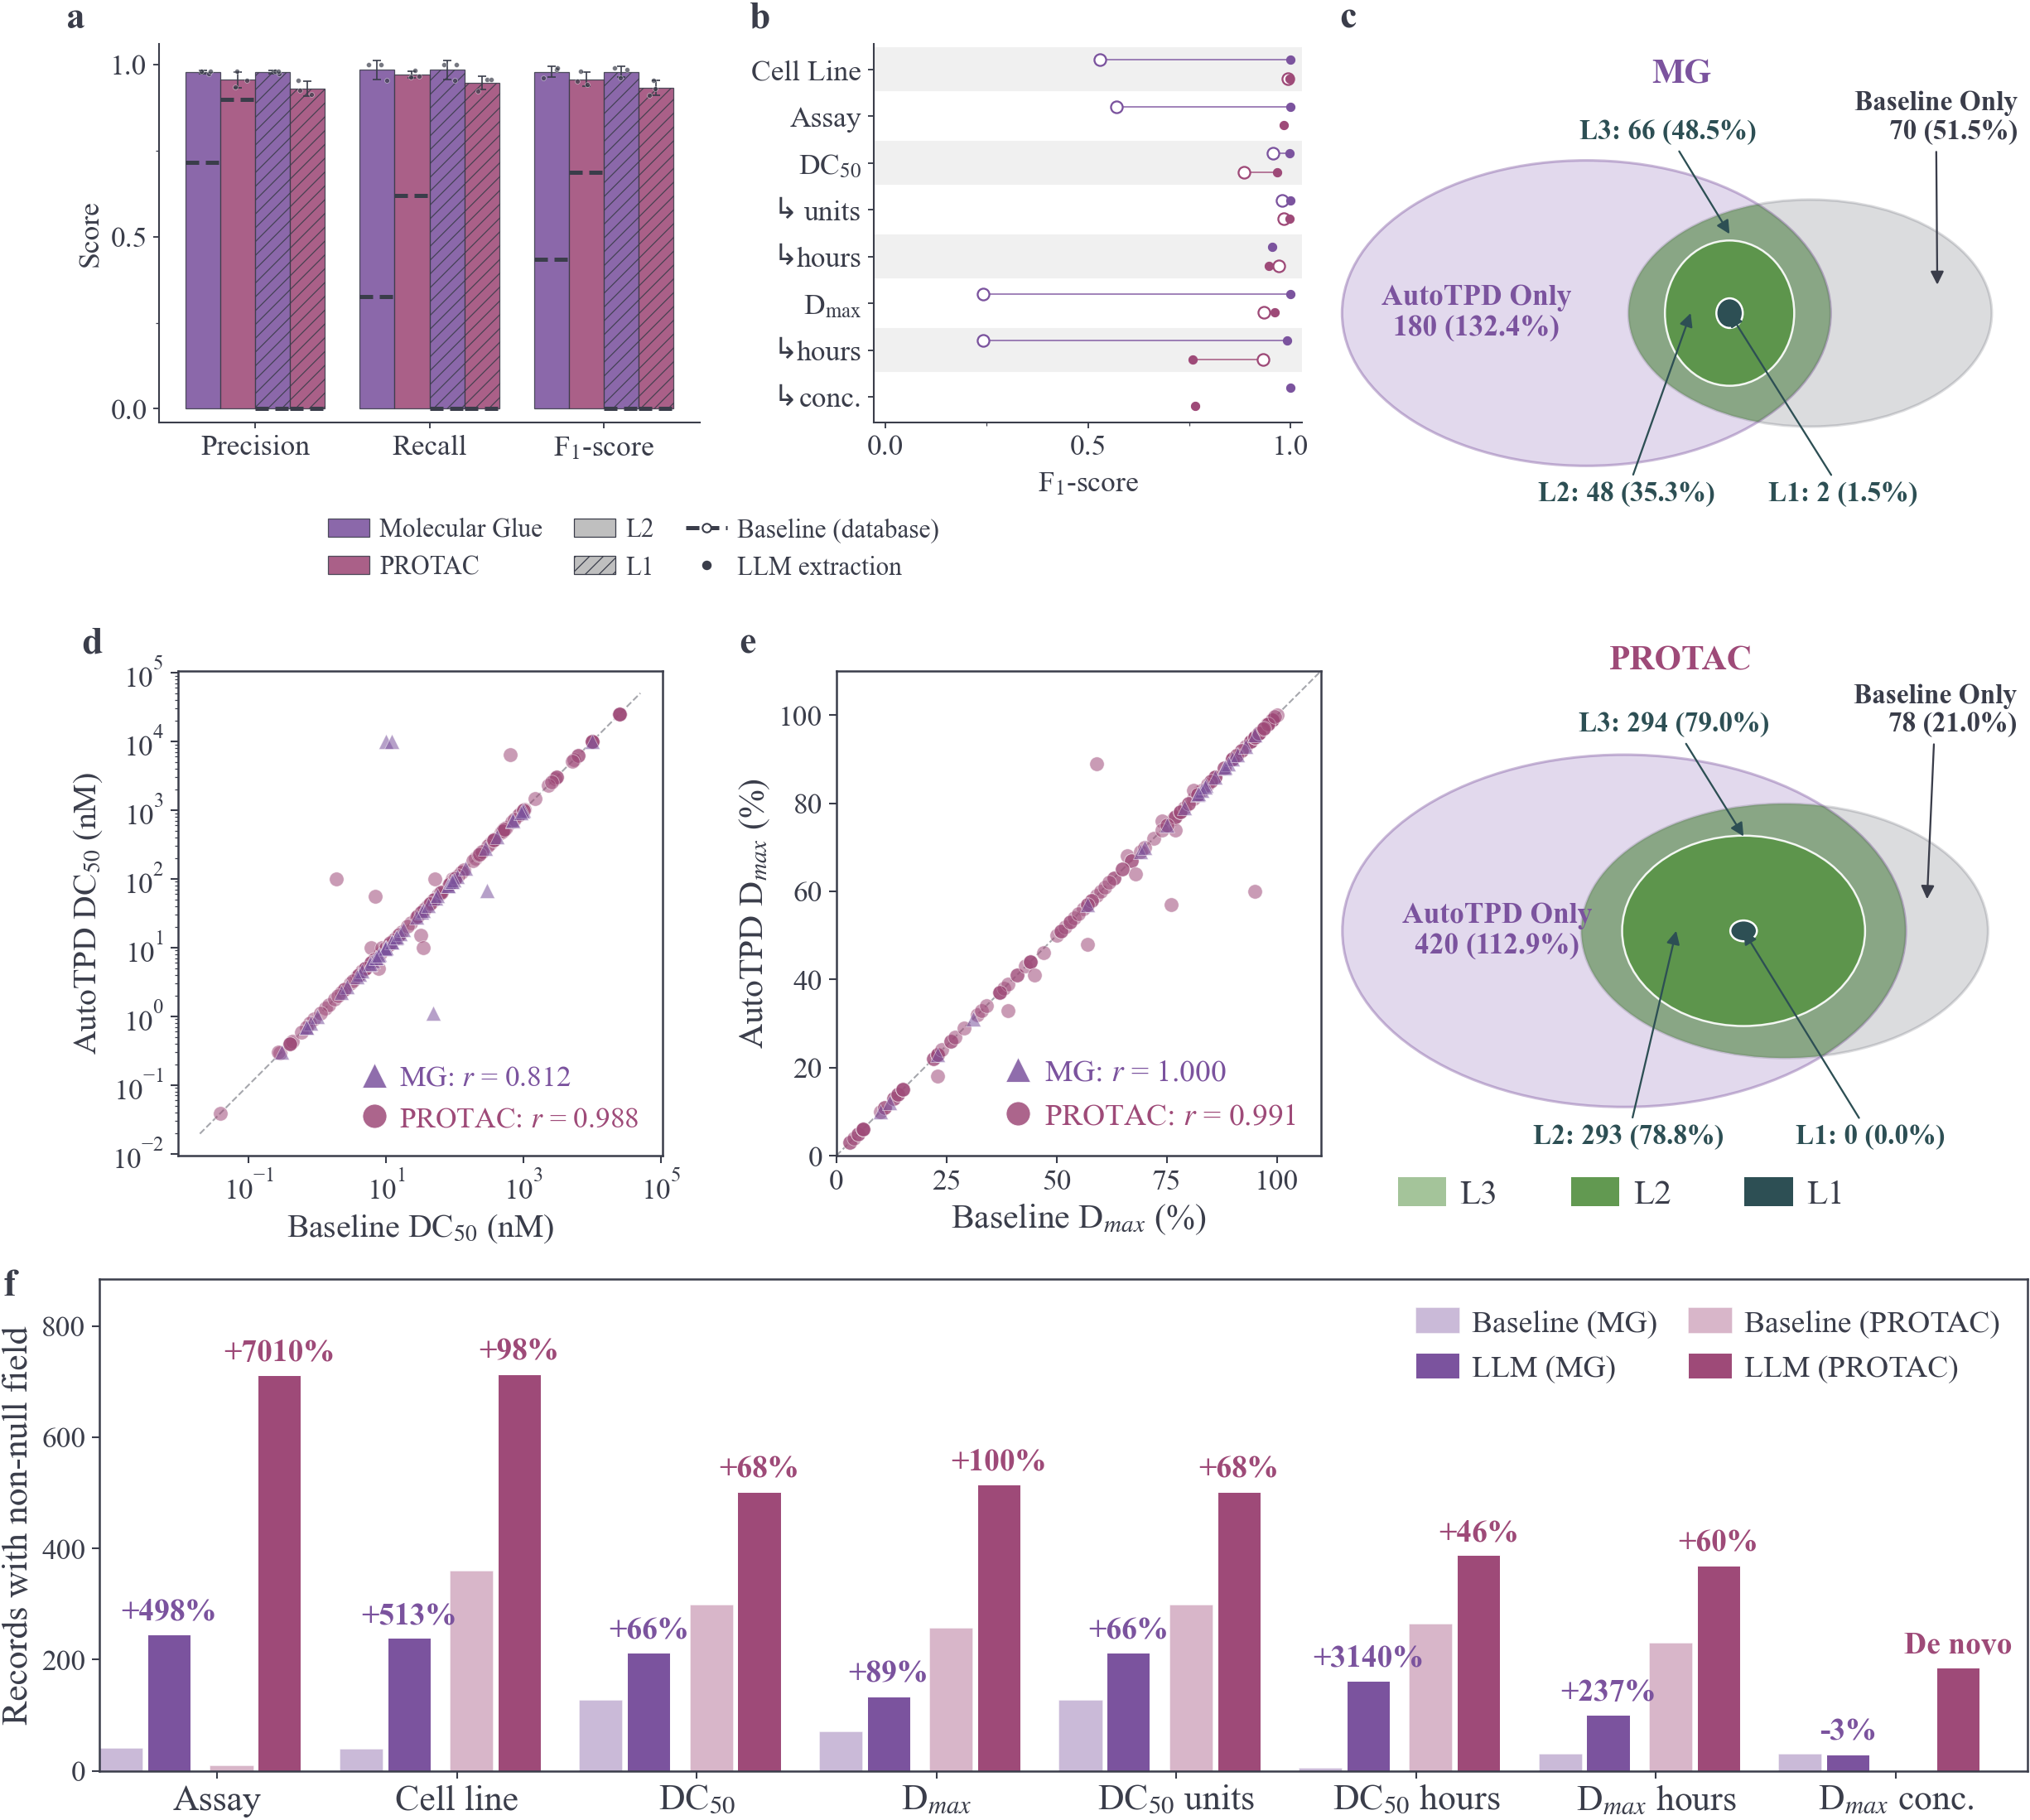

In [20]:
# All positions are in inches. Row 3 keeps the exact axes size of panel (d) in
# process-llm-vs-baseline.ipynb (16 in figure, left=0.02, right=0.99 -> 15.52 in wide,
# 0.92 height ratio of a 2-row grid -> 3.956 in tall) and sets the figure width.
FIG_W = 16.0
ROW3_LEFT, ROW3_W, ROW3_H, ROW3_BOTTOM = 0.32, 15.52, 3.956, 0.60

ROW2_BOTTOM, ROW2_H = 5.55, 3.90
ROW1_BOTTOM, ROW1_H = 11.45, 3.05
FIG_H = ROW1_BOTTOM + ROW1_H + 0.45

VENN_LEFT, VENN_W = 10.30, 5.50
VENN_TOP = ROW1_BOTTOM + ROW1_H
VENN_AX_H, VENN_TOP_PAD, VENN_LEGEND_GAP = 4.3, 0.40, 0.30
VENN_LEGEND_INSET = 0.7

PANEL_FMT = "{}"
PANEL_Y = ROW1_BOTTOM + ROW1_H + 0.06


def add_axes_in(fig, left, bottom, width, height):
    return fig.add_axes([left / FIG_W, bottom / FIG_H, width / FIG_W, height / FIG_H])


def add_panel_label_in(fig, label, left, bottom):
    fig.text(left / FIG_W, bottom / FIG_H, label, fontsize=22, fontweight="bold",
             va="bottom", ha="left", color=DARK_SLATE)


fig = plt.figure(figsize=(FIG_W, FIG_H))

# Row 1: llm-and-baseline-vs-gt (a), (b)
with plt.rc_context(GT_RCPARAMS):
    ax_gt_a = add_axes_in(fig, 0.80, ROW1_BOTTOM, 4.35, ROW1_H)
    ax_gt_b = add_axes_in(fig, 6.55, ROW1_BOTTOM, 3.45, ROW1_H)
    draw_gt_scores(ax_gt_a)
    draw_gt_fields(ax_gt_b)
    ax_gt_a.legend(handles=gt_legend_handles(),
                   loc="upper center", bbox_transform=fig.dpi_scale_trans,
                   bbox_to_anchor=(5.1, ROW1_BOTTOM - 0.78),
                   ncol=3, frameon=False, fontsize=GT_LEGEND_FS,
                   columnspacing=1.2, handletextpad=0.4, handlelength=1.6)

# Row 2: process-llm-vs-baseline (b), (c)
ax_dc50 = add_axes_in(fig, 0.95, ROW2_BOTTOM, ROW2_H, ROW2_H)
ax_dmax = add_axes_in(fig, 6.25, ROW2_BOTTOM, ROW2_H, ROW2_H)
draw_dc50(ax_dc50)
draw_dmax(ax_dmax)

# Right column spanning rows 1-2: process-llm-vs-baseline (a).
# The L1-L3 legend sits at the height of the x-axis labels of (d) / (e);
# MG is pinned to the top of the column and PROTAC just above the legend.
fig.canvas.draw()
xlabel_box = ax_dmax.xaxis.label.get_window_extent().transformed(
    fig.dpi_scale_trans.inverted())
legend_y = (xlabel_box.y0 + xlabel_box.y1) / 2

ax_venn_mg = add_axes_in(fig, VENN_LEFT, VENN_TOP - VENN_TOP_PAD - VENN_AX_H, VENN_W, VENN_AX_H)
ax_venn_pt = add_axes_in(fig, VENN_LEFT, legend_y + VENN_LEGEND_GAP, VENN_W, VENN_AX_H)
ax_venn_mg.set_anchor("N")
ax_venn_pt.set_anchor("S")
draw_venn(ax_venn_mg, mg["topo"], "MG", COL_MG)
draw_venn(ax_venn_pt, pt["topo"], "PROTAC", COL_PT)
venn_legend(ax_venn_pt, loc="center", mode="expand", bbox_transform=fig.dpi_scale_trans,
            bbox_to_anchor=(VENN_LEFT + VENN_LEGEND_INSET, legend_y,
                            VENN_W - 2 * VENN_LEGEND_INSET, 0))

# Row 3: process-llm-vs-baseline (d), unchanged size, full width
ax_counts = add_axes_in(fig, ROW3_LEFT, ROW3_BOTTOM, ROW3_W, ROW3_H)
draw_counts(ax_counts)

add_panel_label_in(fig, PANEL_FMT.format("a"), 0.05, PANEL_Y)
add_panel_label_in(fig, PANEL_FMT.format("b"), 5.55, PANEL_Y)
add_panel_label_in(fig, PANEL_FMT.format("c"), VENN_LEFT, PANEL_Y)
add_panel_label(ax_dc50,   PANEL_FMT.format("d"), -0.20, 1.02)
add_panel_label(ax_dmax,   PANEL_FMT.format("e"), -0.20, 1.02)
add_panel_label(ax_counts, PANEL_FMT.format("f"), -0.05, 0.95)

out_dir = Path("figures")
out_dir.mkdir(exist_ok=True)
fig.savefig(out_dir / "merged_panels.pdf")
fig.savefig(out_dir / "merged_panels.png")
plt.show()
